# 04. Hyperparameter tuning

**Goal.** For Ridge, Random Forest and Gradient Boosting, find good settings **without ever looking at the outer test groups**, and check
for under- and over-fitting.

**How the tuning is nested.** For each outer test group, the settings are chosen using only the four validation combinations inside it
(each of the other four groups is the validation group once). The outer test group is never used. Choosing one setting from all validation
results at once would let every test group's records influence the choice, so that is not done.

**What is searched.**

| Model | Settings |
|---|---|
| Ridge | `alpha` (11 values) |
| Random Forest | trees, depth, minimum leaf size, features per split |
| Gradient Boosting | learning rate, iterations, depth, minimum leaf size, L2 penalty, monotonic constraints (more of any input never lowers the score) |
| all | **feature set** (proposal's 5, the 5 with reviews marked not applicable, the chosen 3), **training labels** (rated only, plus propagated real, plus propagated real and synthetic), **weight** of propagated labels (1 or 0.3) |

Random Forest and Gradient Boosting use a random search of 30 settings per feature set; Ridge is searched exhaustively. The Gradient Boosting here is
scikit-learn's `HistGradientBoostingRegressor`, which reads missing values directly.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"  # tiny data: one thread is faster than OpenMP overhead

sys.path.insert(0, str(Path("training").resolve()))
warnings.filterwarnings("ignore")

import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import ParameterSampler
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from common import RESULTS, SEED, SPLITS, environment, load, log_run
from features import FEATURE_SETS, LABEL_SOURCES, add_team_context, feature_matrix, training_set

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
N_ITER = 30
d = add_team_context(load().set_index("record_id", drop=False))
splits = pd.read_csv(SPLITS)
combos = [(t, v, g[["record_id", "role"]]) for (t, v), g in splits.groupby(["outer_test", "inner_val"])]
GOLD = d[d.label_source == "rater"]
print(environment())
print(len(combos), "combinations;", N_ITER, "random settings per forest or boosting model and feature set")

{'python': '3.11.14', 'numpy': '2.4.6', 'pandas': '3.0.6', 'scipy': '1.17.1', 'sklearn': '1.9.1', 'seed': 20261018, 'data_hash': '2a23bdaa674b', 'splits_hash': 'b5793a57b501'}
20 combinations; 30 random settings per forest or boosting model and feature set


## 1. Search spaces

In [2]:
SPACE = {
    "Ridge": {"alpha": list(np.logspace(-2, 3, 11))},
    "Random Forest": {"n_estimators": [100, 200], "max_depth": [2, 3, 4, 6, None], "min_samples_leaf": [1, 2, 3, 5],
                      "max_features": [0.5, 0.75, 1.0]},
    "Gradient Boosting": {"learning_rate": [0.02, 0.05, 0.1, 0.2], "max_iter": [50, 100, 200, 400], "max_depth": [2, 3, 4, None],
                          "min_samples_leaf": [1, 2, 3, 5, 10], "l2_regularization": [0.0, 0.1, 1.0, 10.0], "monotonic": [False, True]},
}
LABEL_OPTIONS = [("rated only", 1.0), ("rated + propagated (real)", 1.0), ("rated + propagated (real)", 0.3),
                 ("rated + propagated (real + synthetic)", 1.0), ("rated + propagated (real + synthetic)", 0.3)]


def make_model(name, p, n_features):
    if name == "Ridge":
        return make_pipeline(StandardScaler(), Ridge(alpha=p["alpha"]))
    if name == "Random Forest":
        return RandomForestRegressor(random_state=SEED, n_jobs=1, **p)
    q = {k: v for k, v in p.items() if k != "monotonic"}
    return HistGradientBoostingRegressor(random_state=SEED, early_stopping=False, monotonic_cst=[1] * n_features if p["monotonic"] else None, **q)


def fit(model, name, X, y, w):
    model.fit(X, y, **({"ridge__sample_weight": w} if name == "Ridge" else {"sample_weight": w}))
    return model


def settings(name):
    """All configurations to try: (params, label_source, weight)."""
    rng = np.random.RandomState(SEED)
    if name == "Ridge":
        return [({"alpha": a}, ls, w) for a in SPACE["Ridge"]["alpha"] for ls, w in LABEL_OPTIONS]
    draws = list(ParameterSampler(SPACE[name], n_iter=N_ITER, random_state=SEED))
    return [(p, *LABEL_OPTIONS[rng.randint(len(LABEL_OPTIONS))]) for p in draws]


print({m: len(settings(m)) for m in SPACE}, "settings per feature set")
pd.DataFrame({"setting": {m: ", ".join(f"{k}: {v if len(v) <= 6 else str(v[0]) + '...' + str(v[-1])}" for k, v in s.items()) for m, s in SPACE.items()}})

{'Ridge': 55, 'Random Forest': 30, 'Gradient Boosting': 30} settings per feature set


,setting
Ridge,alpha: 0.01...1000.0
Random Forest,"n_estimators: [100, 200], max_depth: [2, 3, 4,..."
Gradient Boosting,"learning_rate: [0.02, 0.05, 0.1, 0.2], max_ite..."


## 2. Training sets, built once

Each (combination, feature set, label source, weight) gets one training set; the scaler and the label model are fitted on that combination's
training rows only (`training/features.py`), and the validation rows are the rated records of the validation group.

In [3]:
_cache = {}


def get_data(ci, fs, kind, label_source, weight):
    key = (ci, fs, kind, label_source, weight)
    if key not in _cache:
        test, val, roles = combos[ci]
        feat = lambda f: feature_matrix(f, fs, kind)  # noqa: E731
        X, y, w, ids = training_set(d, roles, feat, label_source, weight, real_only=False)
        v = d.loc[[i for i in roles[roles.role == "val"].record_id if i in GOLD.index]]
        _cache[key] = (X, y, w, feat(v), v.rater_effort.to_numpy(), v.E_CC.to_numpy(), v.record_id.to_numpy())
    return _cache[key]


# sanity: training and validation never share a record, and validation rows are rated real records
test, val, roles = combos[0]
X, y, w, Xv, yv, cc, rid = get_data(0, FEATURE_SETS[0], "linear", "rated + propagated (real)", 1.0)
assert set(rid) <= set(GOLD.index) and not (set(rid) & set(roles[roles.role == "train"].record_id))
print("training rows:", len(y), "| validation rows (rated):", len(yv), "| features:", X.shape[1])

training rows: 45 | validation rows (rated): 4 | features: 5


## 3. Run the search

In [4]:
def evaluate(name, fs, params, label_source, weight):
    kind = "linear" if name == "Ridge" else "tree"
    rows = []
    for ci, (test, val, roles) in enumerate(combos):
        X, y, w, Xv, yv, cc, rid = get_data(ci, fs, kind, label_source, weight)
        model = fit(make_model(name, params, X.shape[1]), name, X, y, w)
        p = np.clip(model.predict(Xv), 0, 1)
        err = np.abs(p - yv)
        rows.append((test, val, float(err.mean()), len(err), float(err[cc > 0].mean()) if (cc > 0).any() else np.nan, float((p - yv).mean())))
    return rows


results = []
config_id = 0
start = time.time()
for name in SPACE:
    for fs in FEATURE_SETS:
        for params, label_source, weight in settings(name):
            config_id += 1
            for test, val, mae, n, mae_active, bias in evaluate(name, fs, params, label_source, weight):
                results.append((config_id, name, fs, json.dumps(params), label_source, weight, test, val, mae, n, mae_active, bias))
    print(f"{name}: done, {config_id} settings so far, {time.time() - start:.0f}s")
tune = pd.DataFrame(results, columns=["config_id", "model", "feature_set", "params", "label_source", "weight", "outer_test", "inner_val", "MAE", "n", "MAE_active", "bias"])
tune.to_csv(RESULTS / "tuning_results.csv", index=False)
print(len(tune), "evaluations;", tune.config_id.nunique(), "settings")

Ridge: done, 165 settings so far, 60s


Random Forest: done, 255 settings so far, 800s


Gradient Boosting: done, 345 settings so far, 1110s
6900 evaluations; 345 settings


## 4. Choosing the settings: per outer test group, using only its inner validation

For each outer test group, a setting's score is its mean MAE over the four validation groups inside it. The setting with the lowest score is
the best; the **simplest setting within one standard error of it** is the one chosen (standard error of the four validation scores).

In [5]:
def complexity(row):
    p = json.loads(row.params)
    label_rank = LABEL_SOURCES.index(row.label_source) + (0.5 if row.weight != 1.0 else 0)
    if row.model == "Ridge":
        return (label_rank, -p["alpha"])
    if row.model == "Random Forest":
        return (label_rank, p["n_estimators"] * (p["max_depth"] or 10))
    return (label_rank, p["max_iter"] * (p["max_depth"] or 6) * p["learning_rate"] + (0 if p["monotonic"] else 0.001))


per_inner = tune.copy()
score = (per_inner.groupby(["model", "feature_set", "outer_test", "config_id"])
         .agg(MAE=("MAE", "mean"), SE=("MAE", lambda s: s.std(ddof=1) / np.sqrt(len(s))), label_source=("label_source", "first"),
              weight=("weight", "first"), params=("params", "first")).reset_index())
chosen = []
for (model, fs, outer), g in score.groupby(["model", "feature_set", "outer_test"]):
    best = g.loc[g.MAE.idxmin()]
    near = g[g.MAE <= best.MAE + best.SE].copy()
    near["complexity"] = near.apply(lambda r: complexity(r), axis=1)
    pick = near.sort_values("complexity").iloc[0]
    chosen.append({"model": model, "feature_set": fs, "outer_test": outer, "config_id": int(pick.config_id), "inner_MAE": pick.MAE,
                   "best_inner_MAE": best.MAE, "n_within_1SE": len(near), "label_source": pick.label_source, "weight": pick.weight, "params": pick.params})
chosen = pd.DataFrame(chosen)
summary = (chosen.groupby(["model", "feature_set"]).agg(inner_MAE=("inner_MAE", "mean"), spread_over_folds=("inner_MAE", "std"),
                                                         best_possible=("best_inner_MAE", "mean")).round(4).sort_values("inner_MAE"))
summary

inner_MAE  spread_over_folds  best_possible
model             feature_set                                                        
Random Forest     3 features (chosen)        0.0509             0.0077         0.0467
                  5 features, review n/a     0.0536             0.0108         0.0459
                  5 features (proposal)      0.0551             0.0138         0.0458
Gradient Boosting 5 features (proposal)      0.0551             0.0107         0.0476
                  5 features, review n/a     0.0565             0.0086         0.0478
                  3 features (chosen)        0.0578             0.0126         0.0490
Ridge             3 features (chosen)        0.0592             0.0138         0.0465
                  5 features (proposal)      0.0668             0.0193         0.0561
                  5 features, review n/a     0.0746             0.0196         0.0573

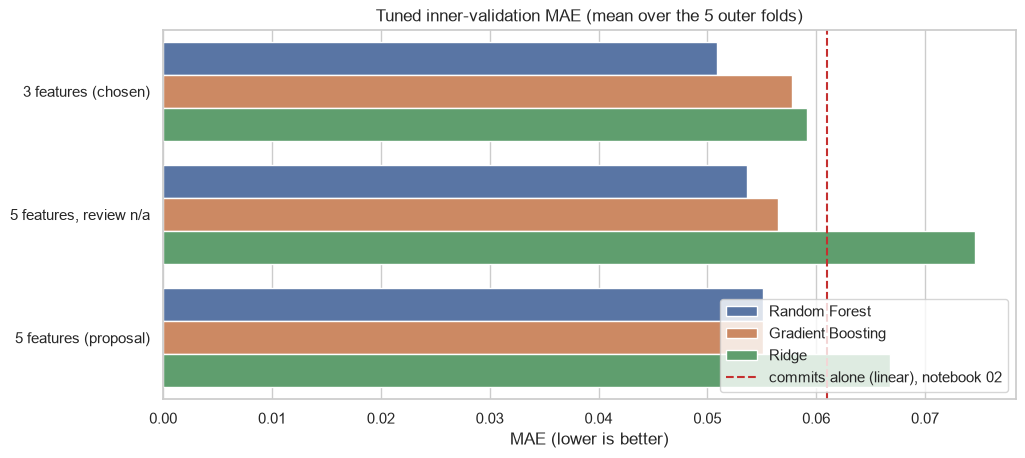

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.8))
plot = summary.reset_index()
sns.barplot(data=plot, y="feature_set", x="inner_MAE", hue="model", ax=ax, palette="deep")
ax.axvline(0.061, color="#c53030", ls="--", label="commits alone (linear), notebook 02")
ax.set(title="Tuned inner-validation MAE (mean over the 5 outer folds)", xlabel="MAE (lower is better)", ylabel="")
ax.legend(loc="lower right")
plt.show()

In [7]:
# what was chosen, per outer fold, for the best feature set of each model
top = summary.reset_index().sort_values("inner_MAE").groupby("model").head(1)[["model", "feature_set"]]
chosen.merge(top, on=["model", "feature_set"]).sort_values(["model", "outer_test"])[["model", "feature_set", "outer_test", "inner_MAE", "n_within_1SE", "label_source", "weight", "params"]].round(4)

,model,feature_set,outer_test,inner_MAE,n_within_1SE,label_source,weight,params
0,Gradient Boosting,5 features (proposal),A,0.0491,15,rated only,1.0,"{""monotonic"": true, ""min_samples_leaf"": 1, ""ma..."
1,Gradient Boosting,5 features (proposal),B,0.0632,20,rated only,1.0,"{""monotonic"": true, ""min_samples_leaf"": 1, ""ma..."
2,Gradient Boosting,5 features (proposal),C,0.0558,19,rated + propagated (real),1.0,"{""monotonic"": false, ""min_samples_leaf"": 3, ""m..."
3,Gradient Boosting,5 features (proposal),D,0.0405,18,rated + propagated (real),1.0,"{""monotonic"": false, ""min_samples_leaf"": 3, ""m..."
4,Gradient Boosting,5 features (proposal),E,0.0671,23,rated + propagated (real),1.0,"{""monotonic"": true, ""min_samples_leaf"": 1, ""ma..."
5,Random Forest,3 features (chosen),A,0.0465,21,rated + propagated (real),1.0,"{""n_estimators"": 100, ""min_samples_leaf"": 2, ""..."
6,Random Forest,3 features (chosen),B,0.0550,25,rated only,1.0,"{""n_estimators"": 200, ""min_samples_leaf"": 1, ""..."
7,Random Forest,3 features (chosen),C,0.0479,24,rated + propagated (real),1.0,"{""n_estimators"": 100, ""min_samples_leaf"": 5, ""..."
8,Random Forest,3 features (chosen),D,0.0428,11,rated + propagated (real),1.0,"{""n_estimators"": 100, ""min_samples_leaf"": 3, ""..."
9,Random Forest,3 features (chosen),E,0.0621,23,rated + propagated (real),1.0,"{""n_estimators"": 100, ""min_samples_leaf"": 2, ""..."


## 5. How sensitive is each model to its settings?

If the error barely moves across the search space, the exact settings do not matter. If it moves a lot, tuning mattered and the choice is
fragile.

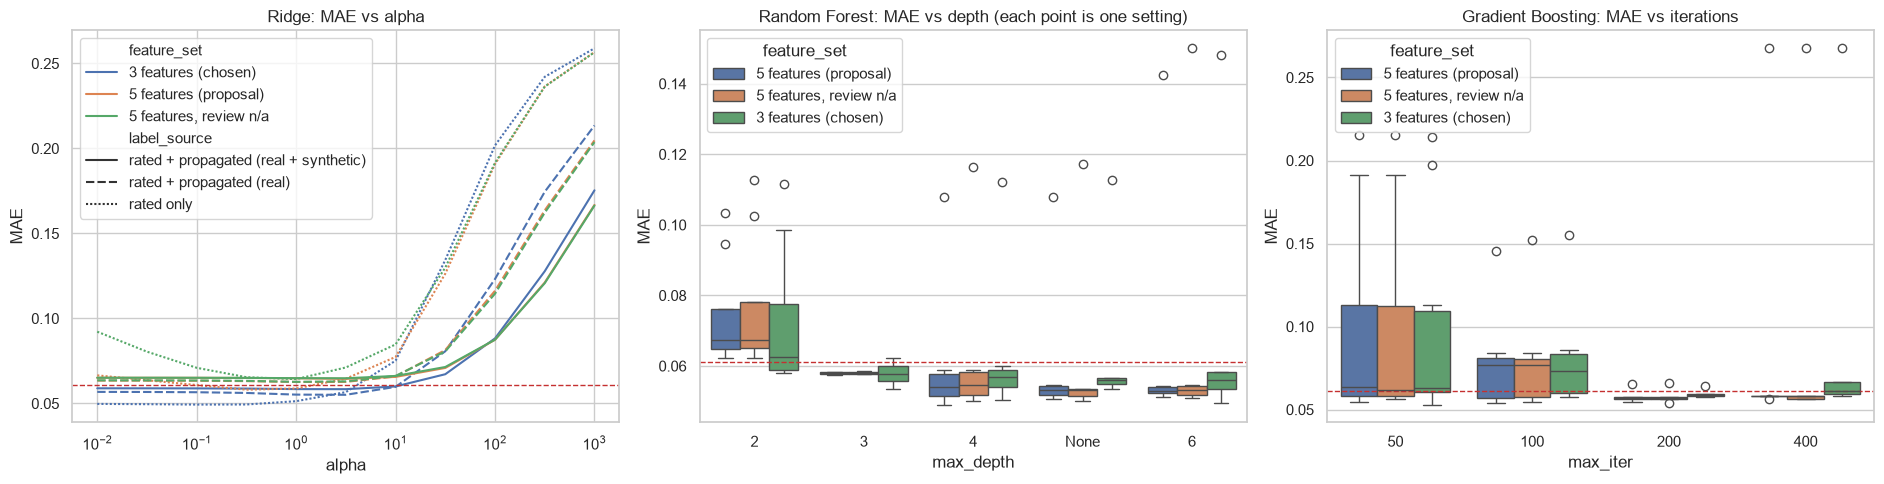

min  median    max
model             feature_set                                 
Gradient Boosting 3 features (chosen)     0.053   0.061  0.268
                  5 features (proposal)   0.054   0.058  0.268
                  5 features, review n/a  0.054   0.059  0.268
Random Forest     3 features (chosen)     0.050   0.058  0.148
                  5 features (proposal)   0.049   0.057  0.142
                  5 features, review n/a  0.050   0.057  0.150
Ridge             3 features (chosen)     0.049   0.059  0.259
                  5 features (proposal)   0.058   0.065  0.257
                  5 features, review n/a  0.062   0.065  0.257

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
r = tune[tune.model == "Ridge"].copy()
r["alpha"] = r.params.map(lambda s: json.loads(s)["alpha"])
sns.lineplot(data=r.groupby(["feature_set", "alpha", "label_source"]).MAE.mean().reset_index(), x="alpha", y="MAE", hue="feature_set", style="label_source", ax=axes[0])
axes[0].set(xscale="log", title="Ridge: MAE vs alpha")
f = tune[tune.model == "Random Forest"].copy()
f["max_depth"] = f.params.map(lambda s: str(json.loads(s)["max_depth"]))
sns.boxplot(data=f.groupby(["config_id", "feature_set", "max_depth"]).MAE.mean().reset_index(), x="max_depth", y="MAE", hue="feature_set", ax=axes[1])
axes[1].set(title="Random Forest: MAE vs depth (each point is one setting)")
g = tune[tune.model == "Gradient Boosting"].copy()
g["max_iter"] = g.params.map(lambda s: json.loads(s)["max_iter"])
sns.boxplot(data=g.groupby(["config_id", "feature_set", "max_iter"]).MAE.mean().reset_index(), x="max_iter", y="MAE", hue="feature_set", ax=axes[2])
axes[2].set(title="Gradient Boosting: MAE vs iterations")
for a in axes:
    a.axhline(0.061, color="#c53030", ls="--", lw=1)
plt.tight_layout()
plt.show()
spread = tune.groupby(["model", "feature_set", "config_id"]).MAE.mean().groupby(["model", "feature_set"]).agg(["min", "median", "max"]).round(3)
spread

## 6. Under- and over-fitting: learning curves and the train-vs-validation gap

For the best feature set of each model, train on 25%, 50%, 75% and 100% of the training rows (three random draws each, at least 4 rows) and
compare the error on the training rows with the error on the validation rows. A big gap that stays open means over-fitting; two high,
close curves mean the model is too simple or the data too thin.

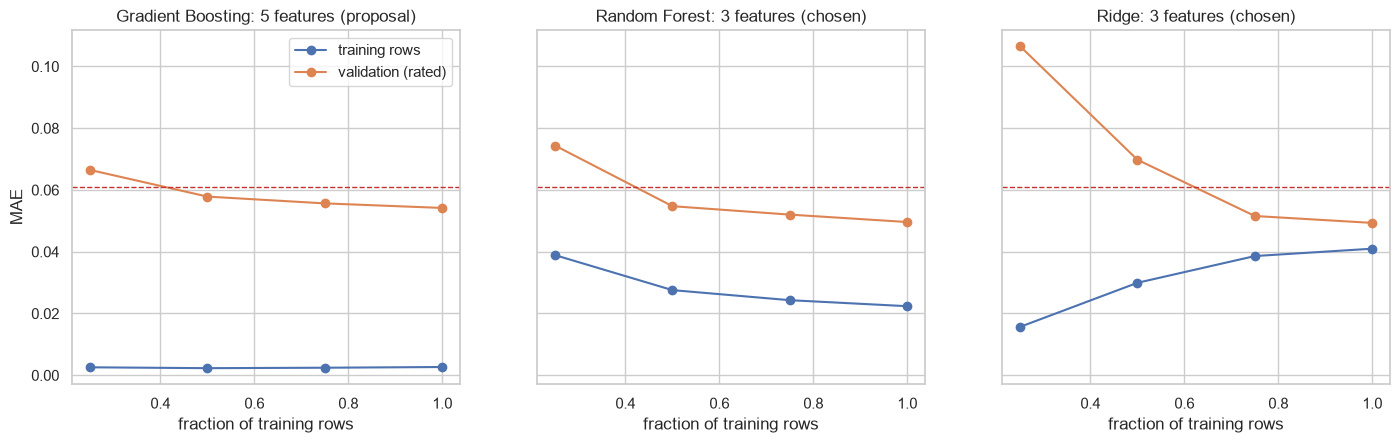

,model,fraction of training rows,train MAE,validation MAE
0,Gradient Boosting,0.25,0.003,0.066
1,Gradient Boosting,0.50,0.002,0.058
2,Gradient Boosting,0.75,0.002,0.056
3,Gradient Boosting,1.00,0.003,0.054
4,Random Forest,0.25,0.039,0.074
5,Random Forest,0.50,0.028,0.055
6,Random Forest,0.75,0.024,0.052
7,Random Forest,1.00,0.022,0.050
8,Ridge,0.25,0.016,0.107
9,Ridge,0.50,0.030,0.070


In [9]:
def best_config(model):
    fs = summary.reset_index().query("model == @model").sort_values("inner_MAE").iloc[0].feature_set
    g = tune[(tune.model == model) & (tune.feature_set == fs)].groupby("config_id").MAE.mean()
    row = tune[tune.config_id == g.idxmin()].iloc[0]
    return fs, json.loads(row.params), row.label_source, row.weight


curves = []
rng = np.random.RandomState(SEED)
for model in SPACE:
    fs, params, label_source, weight = best_config(model)
    kind = "linear" if model == "Ridge" else "tree"
    for frac in (0.25, 0.5, 0.75, 1.0):
        for draw in range(3 if frac < 1 else 1):
            tr, va = [], []
            for ci in range(len(combos)):
                X, y, w, Xv, yv, cc, rid = get_data(ci, fs, kind, label_source, weight)
                k = max(4, int(round(frac * len(y))))
                idx = rng.choice(len(y), min(k, len(y)), replace=False) if frac < 1 else np.arange(len(y))
                m = fit(make_model(model, params, X.shape[1]), model, X[idx], y[idx], w[idx])
                tr.append(np.average(np.abs(np.clip(m.predict(X[idx]), 0, 1) - y[idx]), weights=w[idx]))
                va.append(np.abs(np.clip(m.predict(Xv), 0, 1) - yv).mean())
            curves.append((model, frac, np.mean(tr), np.mean(va)))
lc = pd.DataFrame(curves, columns=["model", "fraction of training rows", "train MAE", "validation MAE"]).groupby(["model", "fraction of training rows"]).mean().reset_index()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)
for a, (model, g) in zip(axes, lc.groupby("model")):
    a.plot(g["fraction of training rows"], g["train MAE"], "o-", label="training rows")
    a.plot(g["fraction of training rows"], g["validation MAE"], "o-", label="validation (rated)")
    a.axhline(0.061, color="#c53030", ls="--", lw=1)
    a.set(title=f"{model}: {best_config(model)[0]}", xlabel="fraction of training rows")
axes[0].set_ylabel("MAE"); axes[0].legend()
plt.show()
lc.round(3)

## 7. Save the choices and log

In [10]:
out = {}
for (model, fs), g in chosen.groupby(["model", "feature_set"]):
    out.setdefault(model, {})[fs] = {r.outer_test: {"params": json.loads(r.params), "label_source": r.label_source, "weight": float(r.weight),
                                                    "inner_MAE": round(float(r.inner_MAE), 4)} for r in g.itertuples()}
(RESULTS / "tuning_choices.json").write_text(json.dumps(out, indent=1))
for r in summary.reset_index().itertuples():
    log_run("04_hyperparameter_tuning", r.model, f"{r.feature_set}; nested inner validation, mean of 5 outer folds", {"MAE": round(r.inner_MAE, 4), "SE": round(r.spread_over_folds, 4)})
print("saved results/tuning_choices.json and results/tuning_results.csv; logged to results/runs.csv")

saved results/tuning_choices.json and results/tuning_results.csv; logged to results/runs.csv


## 8. Reading the results

Tuned **inner-validation MAE** (mean over the 5 outer folds; each fold's setting chosen using only that fold's four validation groups):

| Model | 3 features (chosen) | 5 features, review n/a | 5 features (proposal) |
|---|---|---|---|
| Random Forest | **0.051** | 0.054 | 0.055 |
| Gradient Boosting | 0.058 | 0.057 | 0.055 |
| Ridge | 0.059 | 0.075 | 0.067 |

For reference (notebook 02, untuned): commits alone 0.053 (normalised) and 0.061 (linear), Ridge on all five features 0.073.

**What the search shows**

- **Tuning helped Ridge and the forest a lot.** Ridge on the proposal's five features improved from 0.073 to 0.067 and on the chosen three to 0.059.
  The forest on three features reached 0.051.
- **The feature set matters less than the model.** Marking reviews as not applicable did not help any model; the proposal's five features
  and the chosen three give similar forest and boosting results (0.051-0.055).
- **Propagated labels now help the tree models.** The forest chose "rated + propagated (real)" in 4-5 of the 5 folds and boosting in 1-3 of 5,
  while Ridge always chose rated only. Trees need many rows; the propagated rows supply them, at the price of
  learning part of the label model's own shape.
- **Settings are not fragile.** Across the forest's 90 settings the median error is 0.057-0.058 against a best of 0.049-0.050; boosting is
  similar (median 0.058-0.061). A few poor settings go as high as 0.15-0.27 (very shallow or very over-regularised models); sensible ones sit
  in a narrow band.

**Under- and over-fitting (learning curves, best setting per model)**

- Ridge: training and validation error converge as data grows (0.041 vs 0.049): no over-fitting, limited by the model.
- Random Forest: training 0.022 vs validation 0.050: a gap, but validation keeps falling with more rows (0.074 -> 0.050).
- Gradient Boosting: training error is almost zero (0.003) against validation 0.054: it memorises the training rows.
- Every curve is still falling at 100% of the training rows, so **more data would help**. This is a data-quantity limit, not a model limit.

**Be careful with the comparison.** The tuned scores are the *best of many settings* picked on the same validation groups they are reported
on. The gap between the median setting (0.057-0.058) and the chosen one (0.051) shows how much of the apparent gain over the untuned
baselines (0.053-0.061) is selection. The forest's lead is real in the sense that it is consistent across feature sets, but its edge over
commits alone is within the noise. The unbiased number comes only from the outer test groups in notebook 08.

**Saved:** `training/results/tuning_choices.json` (settings per model, feature set and outer fold) and `tuning_results.csv`.
Next: **05. Model comparison**.